# Handwritten digit classification and adversarial robustness

A walkthrough of the trained models. Training and full evaluation are scripts (`python -m digits.train`, `python -m digits.evaluate`); this notebook loads the saved checkpoints and reproduces the key results interactively.

**Data protocol.** Models are trained on 55,000 of the official 60,000 training images, model selection uses the other 5,000 (validation), and the official 10,000-image test set is used only for the numbers reported here.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import numpy as np
import torch
import matplotlib.pyplot as plt

from digits.data import load_mnist
from digits.models import load_checkpoint, count_params
from digits.attacks import fgsm, pgd

torch.manual_seed(0)
splits = load_mnist('data')
x_test, y_test = splits.test.tensors
print({k: len(getattr(splits, k)) for k in ['train', 'val', 'test']})

{'train': 55000, 'val': 5000, 'test': 10000}


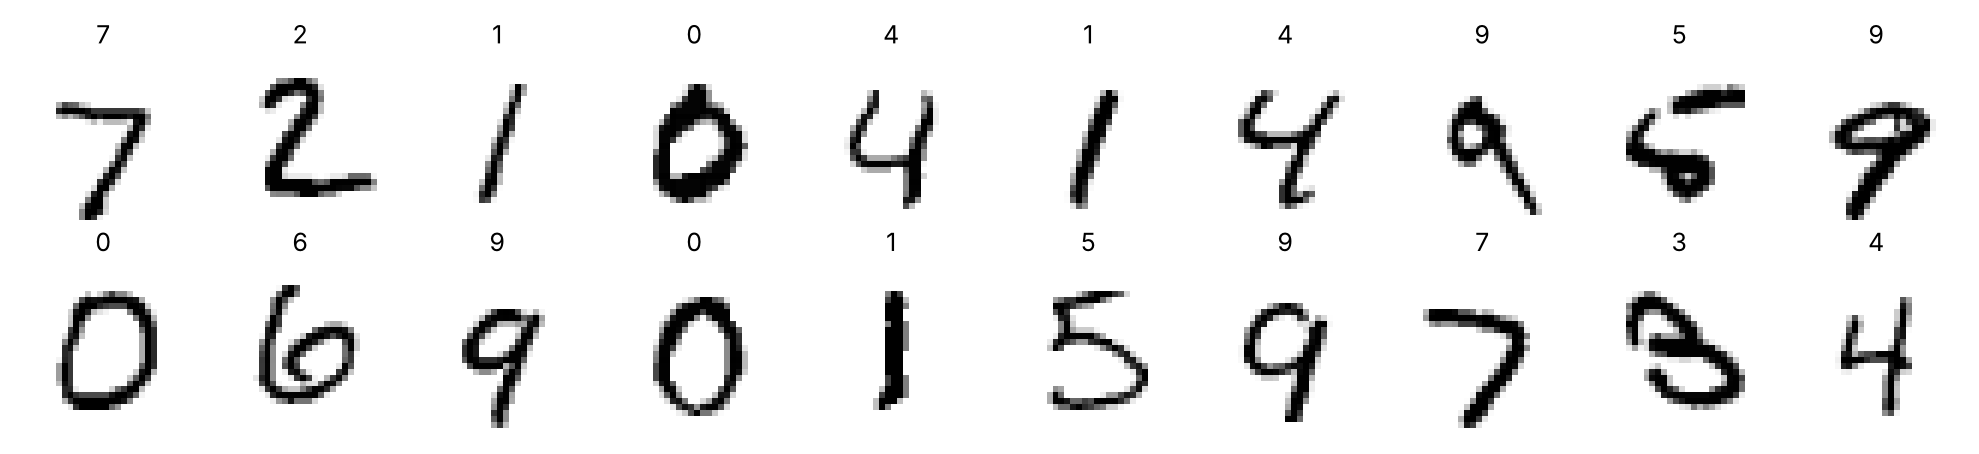

In [2]:
fig, axes = plt.subplots(2, 10, figsize=(10, 2.3))
for ax, i in zip(axes.ravel(), range(20)):
    ax.imshow(x_test[i, 0], cmap='gray_r'); ax.set_title(int(y_test[i]), fontsize=9); ax.axis('off')
plt.tight_layout()

## Clean test accuracy

In [3]:
models = {k: load_checkpoint(f'checkpoints/{k}.pt') for k in ['mlp', 'cnn', 'cnn_adv']}

@torch.no_grad()
def accuracy(model, x, y, bs=1000):
    return sum((model(x[i:i+bs]).argmax(1) == y[i:i+bs]).sum().item() for i in range(0, len(x), bs)) / len(x)

for k, m in models.items():
    print(f'{k:8s} params={count_params(m):>8,}  test acc={accuracy(m, x_test, y_test):.2%}')

mlp      params=  84,060  test acc=97.88%


cnn      params= 468,010  test acc=99.62%


cnn_adv  params= 468,010  test acc=98.78%


## Untargeted attack: FGSM vs PGD

FGSM takes one step of size ε in the direction of the sign of the loss gradient. PGD repeats smaller steps and projects back into the ε-ball, so it finds much stronger perturbations. Here: the first 1,000 test images (the full curves are in `results/`).

In [4]:
xs, ys = x_test[:1000], y_test[:1000]
for eps in [0.1, 0.2, 0.3]:
    row = []
    for k, m in models.items():
        a_f = accuracy(m, fgsm(m, xs, ys, eps), ys)
        a_p = accuracy(m, pgd(m, xs, ys, eps, steps=20), ys)
        row.append(f'{k}: FGSM {a_f:6.1%}  PGD {a_p:6.1%}')
    print(f'eps={eps}:  ' + ' | '.join(row))

eps=0.1:  mlp: FGSM  20.0%  PGD   6.7% | cnn: FGSM  26.6%  PGD   6.4% | cnn_adv: FGSM  97.1%  PGD  96.8%


eps=0.2:  mlp: FGSM   4.3%  PGD   0.1% | cnn: FGSM  15.8%  PGD   0.7% | cnn_adv: FGSM  95.5%  PGD  94.7%


eps=0.3:  mlp: FGSM   2.0%  PGD   0.0% | cnn: FGSM  13.0%  PGD   0.0% | cnn_adv: FGSM  93.2%  PGD  90.0%


## Same digits, attacked against each model

One correctly classified digit per class, PGD with ε = 0.15.

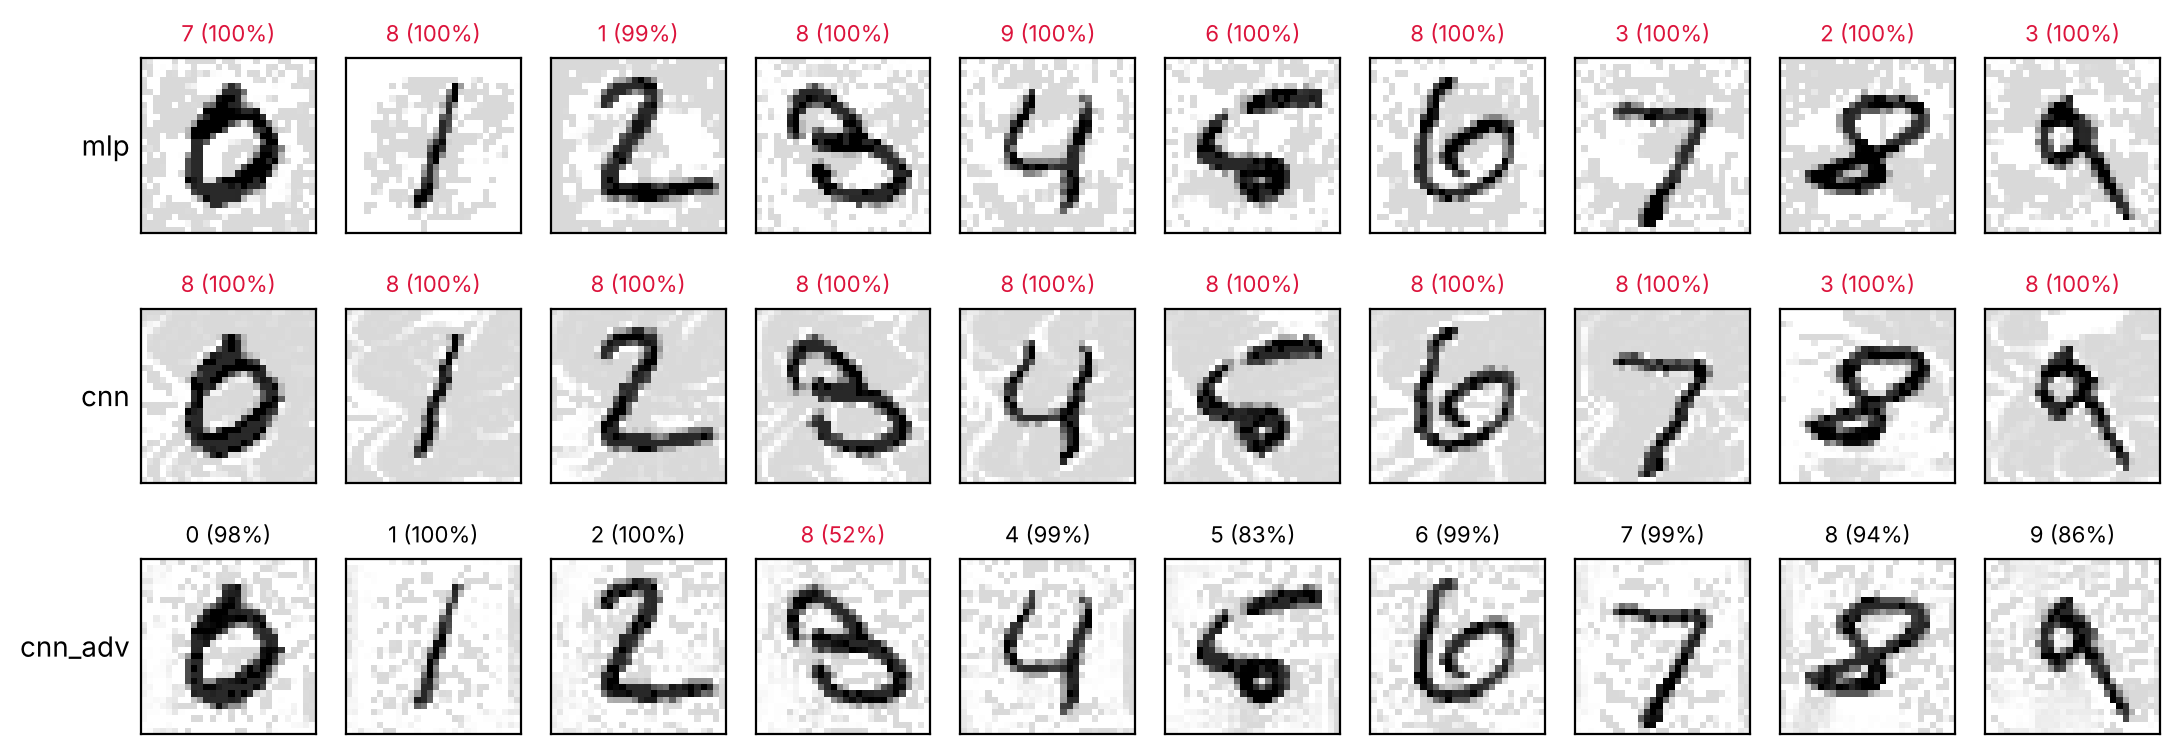

In [5]:
idx = [int(torch.where(y_test == c)[0][0]) for c in range(10)]
xb, yb = x_test[idx], y_test[idx]
fig, axes = plt.subplots(3, 10, figsize=(11, 4))
for r, (k, m) in enumerate(models.items()):
    xa = pgd(m, xb, yb, 0.15, steps=40)
    with torch.no_grad():
        p = m(xa).softmax(1)
    for c in range(10):
        ax = axes[r, c]; ax.imshow(xa[c, 0], cmap='gray_r', vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        pred = int(p[c].argmax())
        ax.set_title(f'{pred} ({p[c, pred]:.0%})', fontsize=8, color='black' if pred == c else 'crimson')
        if c == 0: ax.set_ylabel(k, rotation=0, ha='right', va='center')
plt.tight_layout()

## Targeted attack

Targeted PGD pushes a digit toward a chosen class by *decreasing* the loss on the target label (the original project's 4→9, 7→8, 9→7 example).

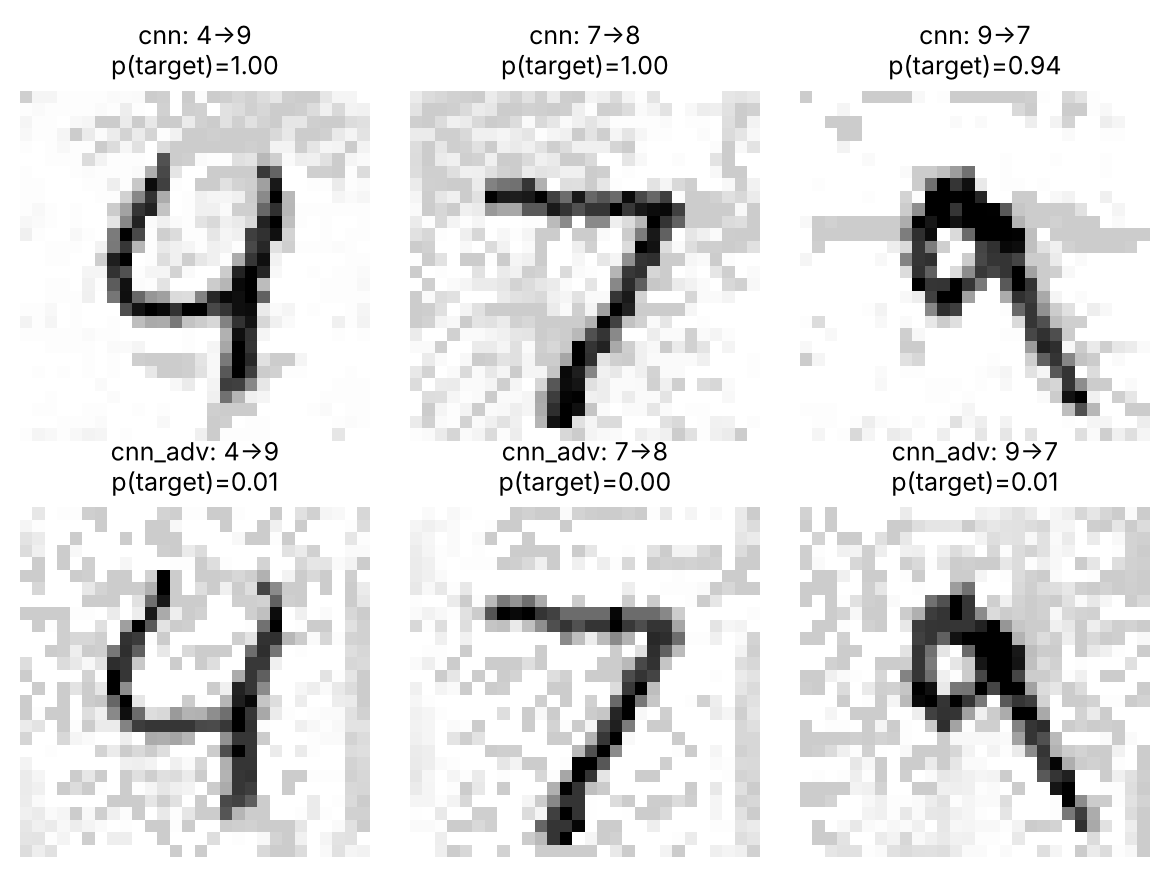

In [6]:
src = [4, 7, 9]; tgt = torch.tensor([9, 8, 7])
xb = x_test[[idx[s] for s in src]]
fig, axes = plt.subplots(2, 3, figsize=(6, 4.4))
for r, k in enumerate(['cnn', 'cnn_adv']):
    m = models[k]
    xa = pgd(m, xb, tgt, eps=0.2, steps=100, alpha=0.01, targeted=True)
    with torch.no_grad():
        p = m(xa).softmax(1)
    for c in range(3):
        ax = axes[r, c]; ax.imshow(xa[c, 0], cmap='gray_r', vmin=0, vmax=1); ax.axis('off')
        ax.set_title(f'{k}: {src[c]}→{int(tgt[c])}\np(target)={p[c, tgt[c]]:.2f}', fontsize=9)
plt.tight_layout()

The standard CNN can be steered to almost any chosen class within ε = 0.2, while the adversarially trained CNN keeps the true label in nearly every case (see `results/figures/targeted_attack_*.png` for the full 10 × 10 grids).